In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# Load dataset
df = sns.load_dataset("penguins")

# Check the data
print(df.head())
print(df.info())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_

/tmp/ipykernel_4296/1662729907.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="species", y="body_mass_g", errorbar=None,palette=['maroon','red','beige'])


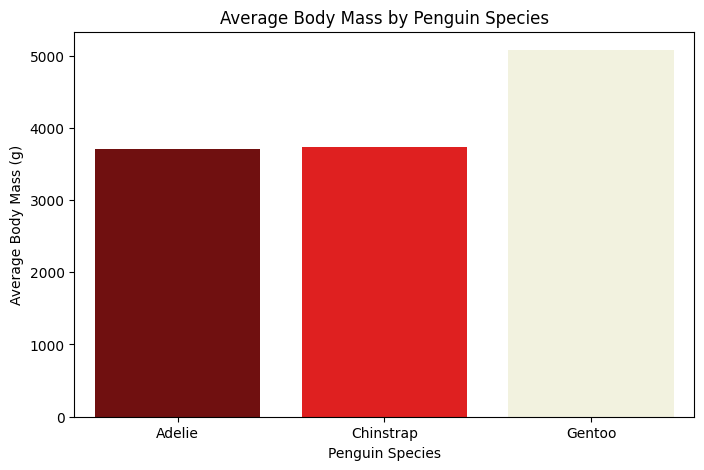

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="species", y="body_mass_g", errorbar=None,palette=['maroon','red','beige'])

plt.xlabel("Penguin Species")
plt.ylabel("Average Body Mass (g)")
plt.title("Average Body Mass by Penguin Species")

plt.show()

/tmp/ipykernel_4296/3720177133.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="species", palette=['orange', 'blue', 'pink'])


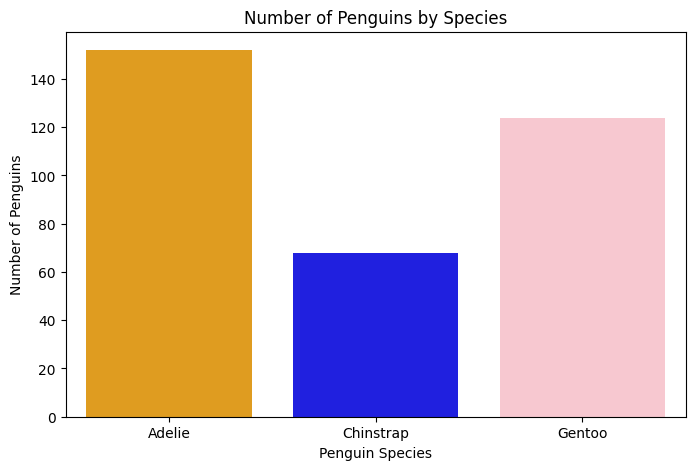

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species", palette=['orange', 'blue', 'pink'])

plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")
plt.title("Number of Penguins by Species")

plt.show()

print(df["species"].value_counts())

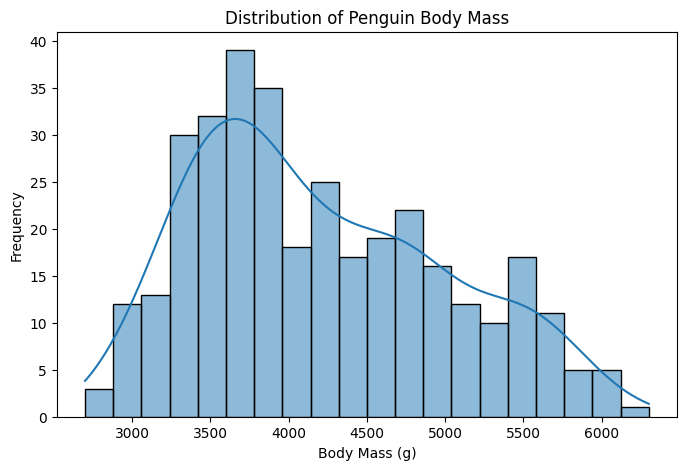

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="body_mass_g", bins=20, kde=True)

plt.xlabel("Body Mass (g)")
plt.ylabel("Frequency")
plt.title("Distribution of Penguin Body Mass")

plt.show()

/tmp/ipykernel_4296/561453460.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y="body_mass_g", palette =['black','brown','maroon'])


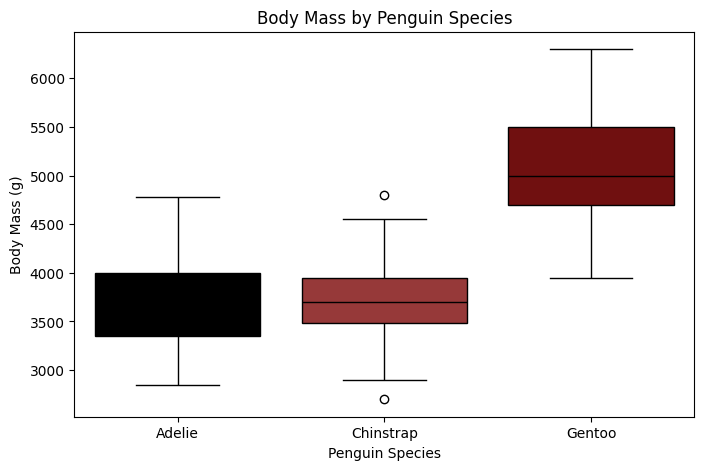

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="species", y="body_mass_g", palette =['black','brown','maroon'])

plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (g)")
plt.title("Body Mass by Penguin Species")

plt.show()

In [ ]:
Q1 = df["body_mass_g"].quantile(0.25)
Q3 = df["body_mass_g"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["body_mass_g"] < lower) |
    (df["body_mass_g"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Number of outliers:", len(outliers))

Q1: 3550.0
Q3: 4750.0
IQR: 1200.0
Lower Bound: 1750.0
Upper Bound: 6550.0
Number of outliers: 0


In [ ]:
df["zscore"] = stats.zscore(df["body_mass_g"], nan_policy="omit")

outliers_z = df[df["zscore"].abs() > 3]

print("Number of z-score outliers:", len(outliers_z))

Number of z-score outliers: 0


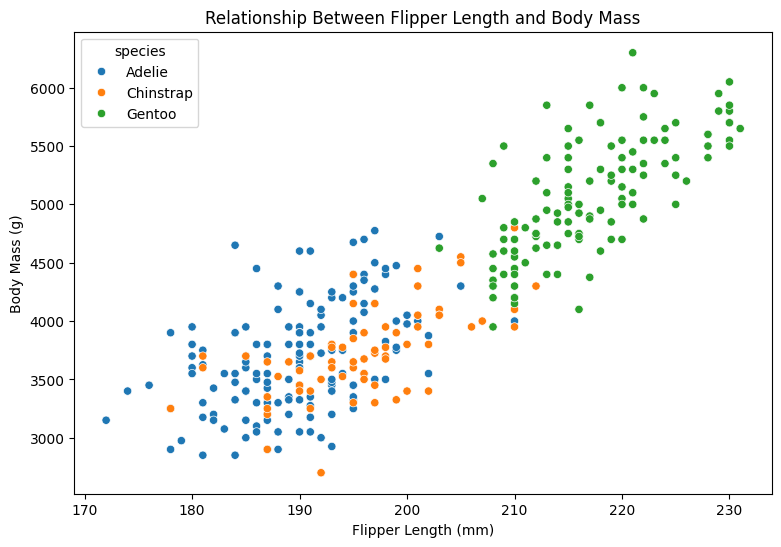

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species"
)

plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.title("Relationship Between Flipper Length and Body Mass")

plt.show()

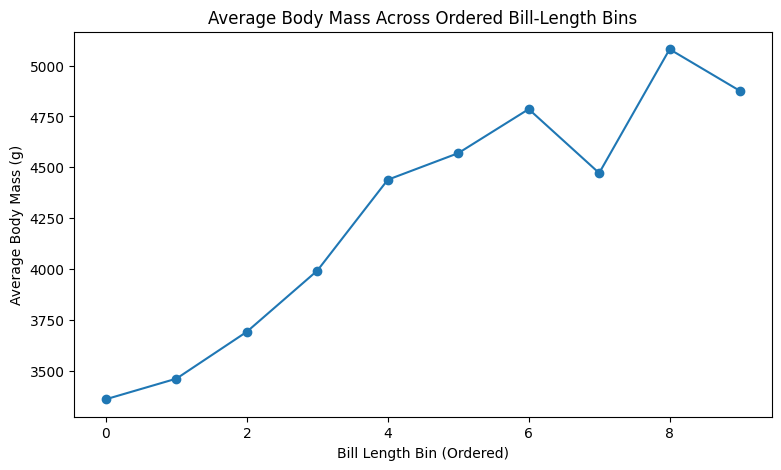

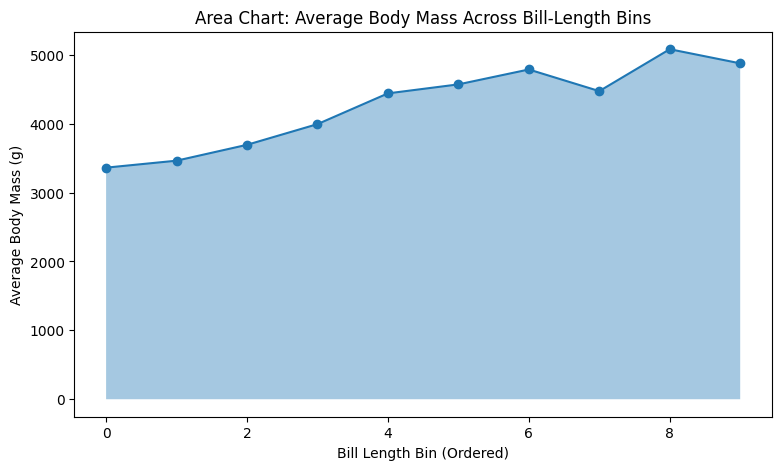

In [ ]:
# Create ordered bill-length bins
df["bill_length_bin"] = pd.cut(
    df["bill_length_mm"],
    bins=10
)

# Calculate average body mass for each bin
trend = df.groupby(
    "bill_length_bin",
    observed=True
)["body_mass_g"].mean().reset_index()

# Use bin labels as x-axis values
trend["bin_number"] = range(len(trend))

plt.figure(figsize=(9, 5))

plt.plot(
    trend["bin_number"],
    trend["body_mass_g"],
    marker="o"
)

plt.xlabel("Bill Length Bin (Ordered)")
plt.ylabel("Average Body Mass (g)")
plt.title("Average Body Mass Across Ordered Bill-Length Bins")

plt.show()

plt.figure(figsize=(9, 5))

plt.fill_between(
    trend["bin_number"],
    trend["body_mass_g"],
    alpha=0.4
)

plt.plot(
    trend["bin_number"],
    trend["body_mass_g"],
    marker="o"
)

plt.xlabel("Bill Length Bin (Ordered)")
plt.ylabel("Average Body Mass (g)")
plt.title("Area Chart: Average Body Mass Across Bill-Length Bins")

plt.show()

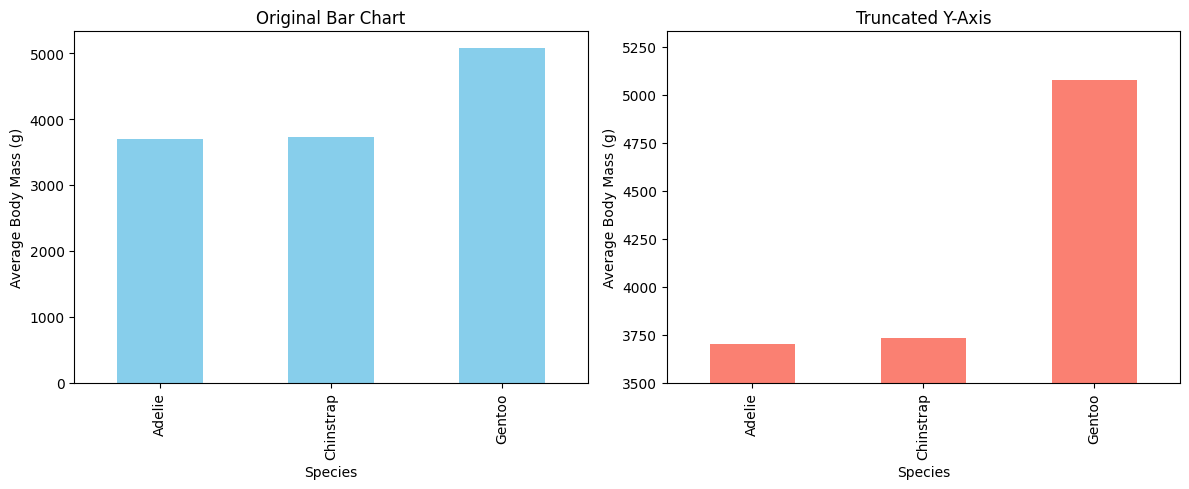

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load penguins dataset
penguins = sns.load_dataset("penguins")

# Calculate average body mass for each species
avg_body_mass = penguins.groupby("species")["body_mass_g"].mean()

# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original chart: y-axis starts at zero
avg_body_mass.plot(kind="bar", ax=axes[0], color="skyblue")
axes[0].set_title("Original Bar Chart")
axes[0].set_ylabel("Average Body Mass (g)")
axes[0].set_xlabel("Species")
axes[0].set_ylim(bottom=0)

# Truncated y-axis
avg_body_mass.plot(kind="bar", ax=axes[1], color="salmon")
axes[1].set_title("Truncated Y-Axis")
axes[1].set_ylabel("Average Body Mass (g)")
axes[1].set_xlabel("Species")

# Deliberately start above the minimum value
axes[1].set_ylim(bottom=3500)

plt.tight_layout()
plt.show()